## Make sure DataSet Loaded

In [6]:
from pathlib import Path

DATA_DIR = Path("datasets")

if not DATA_DIR.exists():
    import kagglehub
    path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")
    print("Downloaded to:", path)
    
else:
    print("Dataset found, skipping download")   

Dataset found, skipping download


In [7]:
print([p.name for p in DATA_DIR.iterdir()]) 

['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


## define SEED = 42

In [42]:
SEED = 42

## Build df

In [12]:
import pandas as pd

classes = ["COVID","Lung_Opacity" ,"Normal", "Viral Pneumonia"]

rows = []
for c in classes:
    for p in (DATA_DIR / c /"images").glob("*.png"):
        rows.append({"path": str(p.relative_to(DATA_DIR)), "label": c})

full_df = pd.DataFrame(rows)
print(len(full_df))
print(full_df.head())

21165
                          path  label
0     COVID\images\COVID-1.png  COVID
1    COVID\images\COVID-10.png  COVID
2   COVID\images\COVID-100.png  COVID
3  COVID\images\COVID-1000.png  COVID
4  COVID\images\COVID-1001.png  COVID


## Count each label

label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64


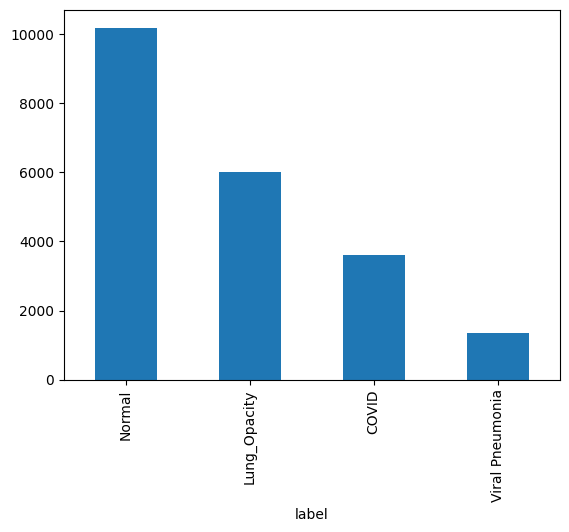

In [14]:
full_df["label"].value_counts().plot.bar()
print(full_df["label"].value_counts())

## Show sample of images

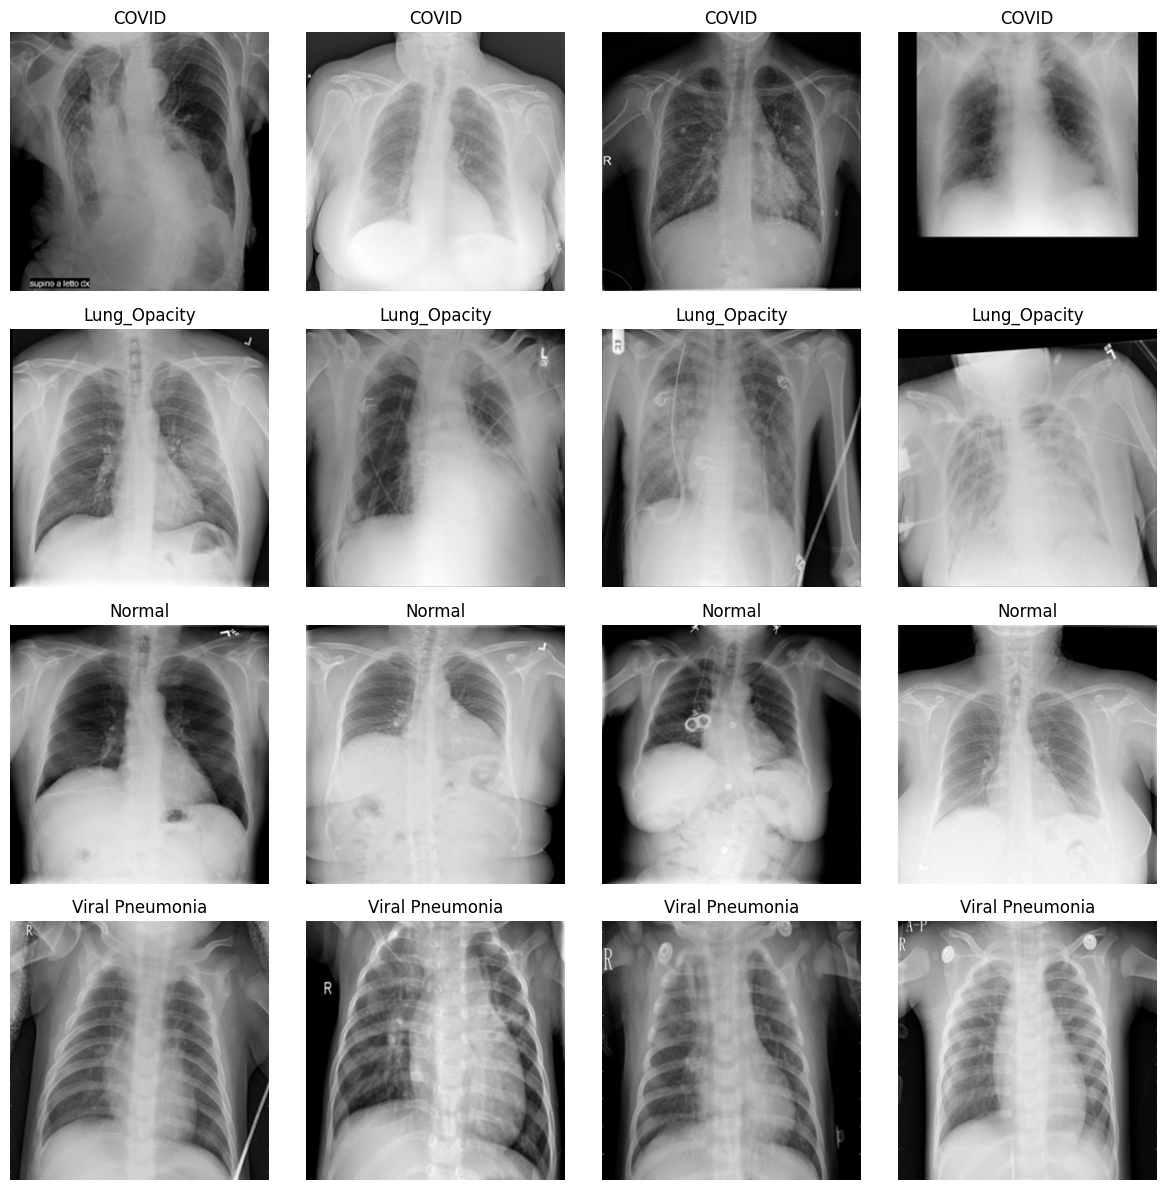

In [20]:
import matplotlib.pyplot as plt
from PIL import Image

classes = ["COVID","Lung_Opacity" ,"Normal", "Viral Pneumonia"]

fig, axs = plt.subplots(len(classes), 4, figsize=(12, 12))

for i, c in enumerate(classes):
    samples = full_df[full_df["label"] == c].sample(4, random_state=42)
    for j, row in enumerate(samples["path"]):
        img = Image.open(DATA_DIR / row)
        axs[i, j].imshow(img, cmap="gray")
        axs[i, j].set_title(c)
        axs[i, j].axis("off")

plt.tight_layout()        
plt.show()


## image format , layers and duplicates 

In [23]:
from PIL import Image
from collections import Counter

modes = Counter()
sizes = Counter()
bad_files = []

for p in full_df["path"]:
    try:
        with Image.open(DATA_DIR / p) as im:
            modes[im.mode] += 1
            sizes[im.size] += 1     
    except Exception:
        bad_files.append(p)

print("Modes:", modes)
print("Sizes:", sizes)
print("Unreadable files:", len(bad_files))

Modes: Counter({'L': 21025, 'RGB': 140})
Sizes: Counter({(299, 299): 21165})
Unreadable files: 0


In [26]:
rgb_paths = []
for p in full_df["path"]:
    with Image.open(DATA_DIR / p) as im:
        if im.mode != "L":
            rgb_paths.append(p)

rgb_df = full_df[full_df["path"].isin(rgb_paths)]
print(rgb_df["label"].value_counts())

label
Viral Pneumonia    140
Name: count, dtype: int64


In [27]:
full_df = full_df[~full_df["path"].isin(rgb_paths)].reset_index(drop=True)

print(len(full_df))
print(full_df["label"].value_counts())

21025
label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1205
Name: count, dtype: int64


In [28]:
import hashlib

def file_hash(path):
    with open(DATA_DIR / path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

full_df["hash"] = full_df["path"].apply(file_hash)
print(full_df["hash"].duplicated().sum())

54


In [32]:
full_df = full_df.drop_duplicates(subset="hash").reset_index(drop=True)
print(len(full_df))
print(full_df["label"].value_counts())

20971
label
Normal             10191
Lung_Opacity        6012
COVID               3570
Viral Pneumonia     1198
Name: count, dtype: int64


## Make clusters to make the balanced Dataset

the dataset is large for our project so we will take only balanced cluster from each label : 1198

In [ ]:
N = int(full_df["label"].value_counts().min())
print("Number of samples per class:", N)

balanced_df =(
    full_df.groupby("label", group_keys=False)
    .sample(n=N, random_state=SEED)
    .reset_index(drop=True)
)
    
print(balanced_df["label"].value_counts())

Number of samples per class: 1198
label
COVID              1198
Lung_Opacity       1198
Normal             1198
Viral Pneumonia    1198
Name: count, dtype: int64


## Build Balanced Dataset

In [33]:
import shutil
from pathlib import Path

OUT_DIR = Path("balanced_dataset")

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)        

for _, row in balanced_df.iterrows():
    dest = OUT_DIR / row["label"]
    dest.mkdir(parents=True, exist_ok=True)
    shutil.copy(DATA_DIR / row["path"], dest / Path(row["path"]).name)

for c in classes:
    print(c, len(list((OUT_DIR / c).glob("*.png"))))

COVID 1198
Lung_Opacity 1198
Normal 1198
Viral Pneumonia 1198


## Build csv File for balanced data

In [36]:
import pandas as pd
from pathlib import Path

OUT_DIR = Path("balanced_dataset")

rows = []
for f in sorted(OUT_DIR.glob("*/*.png")):
    rows.append({"path": f.relative_to(OUT_DIR).as_posix(), "label": f.parent.name})

bal_df = pd.DataFrame(rows)
bal_df.to_csv("balanced.csv", index=False)

print(len(bal_df))                       
print(bal_df["label"].value_counts())   
print(bal_df["path"].duplicated().sum()) 

4792
label
COVID              1198
Lung_Opacity       1198
Normal             1198
Viral Pneumonia    1198
Name: count, dtype: int64
0


## Some Insights After balancing

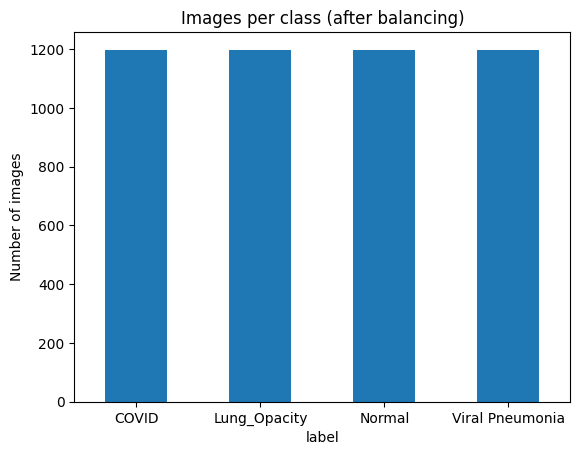

In [39]:
import matplotlib.pyplot as plt

ax = bal_df["label"].value_counts().plot.bar()
ax.set_title("Images per class (after balancing)")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

## Split Dataset

70:15:15

In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split

split_df = pd.read_csv("balanced.csv")                         

train_df, temp_df = train_test_split(
    split_df, test_size=0.30, stratify=split_df["label"], random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

split_df.loc[train_df.index, "split"] = "train"
split_df.loc[val_df.index, "split"] = "val"
split_df.loc[test_df.index, "split"] = "test"

split_df.to_csv("split.csv", index=False)